# Embedding model comparison

Scores computed by `04_evaluate.py` for the seven retrieval methods, on every query in `data/queries.json`, in English and Italian.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path("results")
FIGURES_DIR = RESULTS_DIR / "figures"
BASELINES = ["TF-IDF", "BM25"]
METHOD_NAMES = {
    "TF-IDF": "TF-IDF",
    "BM25": "BM25",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2": "MiniLM",
    "sentence-transformers/paraphrase-multilingual-mpnet-base-v2": "mpnet",
    "intfloat/multilingual-e5-small": "e5-small",
    "intfloat/multilingual-e5-base": "e5-base",
    "BAAI/bge-m3": "bge-m3",
}
SCORE_NAMES = {"ndcg_at_10": "nDCG@10", "precision_at_3": "Precision@3", "mrr_at_10": "MRR@10"}
SELECTION_SCORE = "ndcg_at_10"
BAR_COLORS = {
    SCORE_NAMES[SELECTION_SCORE]: {"en": "#2a78d6", "it": "#eb6834"},
    "Other scores": {"en": "#8c8b84", "it": "#c6c5bd"},
}
LANGUAGE_NAMES = {"en": "English", "it": "Italian"}
TEXT_COLOR = "#52514e"
GRID_COLOR = "#e6e5e0"
RECOMMENDED_BAND_COLOR = "#f1f0ec"

summary = pd.read_csv(RESULTS_DIR / "summary.csv")
per_query = pd.read_csv(RESULTS_DIR / "per_query.csv")
methods = list(dict.fromkeys(summary["method"]))
FIGURES_DIR.mkdir(exist_ok=True)

Mean of each score over all queries, per method and language.

In [2]:
summary_table = summary.pivot(index="method", columns="language", values=list(SCORE_NAMES))
summary_table.columns = [
    f"{SCORE_NAMES[score]} {language}" for score, language in summary_table.columns
]
summary_table.loc[methods].round(3)

,nDCG@10 en,nDCG@10 it,Precision@3 en,Precision@3 it,MRR@10 en,MRR@10 it
method,,,,,,
TF-IDF,0.401,0.035,0.426,0.015,0.556,0.036
BM25,0.499,0.019,0.522,0.012,0.676,0.030
sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,0.429,0.365,0.444,0.383,0.599,0.517
sentence-transformers/paraphrase-multilingual-mpnet-base-v2,0.514,0.452,0.552,0.469,0.633,0.596
intfloat/multilingual-e5-small,0.502,0.248,0.537,0.269,0.715,0.434
intfloat/multilingual-e5-base,0.591,0.234,0.590,0.247,0.732,0.416
BAAI/bge-m3,0.643,0.546,0.633,0.565,0.787,0.739


nDCG@10 by query type. Topic queries are graded against `data/judgements.json`, sequel queries against their one known answer.

In [3]:
ndcg_by_query_type = per_query.pivot_table(
    index="method", columns=["query_type", "language"], values="ndcg_at_10"
)
ndcg_by_query_type.loc[methods].round(3)

query_type                                         sequel         topic       
language                                               en     it     en     it
method                                                                        
TF-IDF                                              0.125  0.107  0.423  0.029
BM25                                                0.129  0.036  0.528  0.017
sentence-transformers/paraphrase-multilingual-M...  0.045  0.000  0.460  0.395
sentence-transformers/paraphrase-multilingual-m...  0.233  0.136  0.536  0.477
intfloat/multilingual-e5-small                      0.098  0.090  0.535  0.261
intfloat/multilingual-e5-base                       0.420  0.329  0.605  0.226
BAAI/bge-m3                                         0.401  0.369  0.663  0.561

The recommended model is the embedding model with the highest nDCG@10 averaged equally over English and Italian. TF-IDF and BM25 are shown for comparison only.

In [4]:
mean_ndcg = summary.groupby("method")["ndcg_at_10"].mean().sort_values(ascending=False)
recommended_model = mean_ndcg.drop(BASELINES).idxmax()
print(mean_ndcg.round(3).to_string())
print(f"\nRecommended model: {recommended_model}")

method
BAAI/bge-m3                                                    0.595
sentence-transformers/paraphrase-multilingual-mpnet-base-v2    0.483
intfloat/multilingual-e5-base                                  0.412
sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2    0.397
intfloat/multilingual-e5-small                                 0.375
BM25                                                           0.259
TF-IDF                                                         0.218

Recommended model: BAAI/bge-m3


The chart shows the three scores of every method, ordered by that average, with the recommended model shaded. In each pair of bars the left one is English and the right one is Italian. nDCG@10 is in colour (blue for English, orange for Italian) because it is the score that picks the model. The chart is also saved as `results/figures/scores.png`.

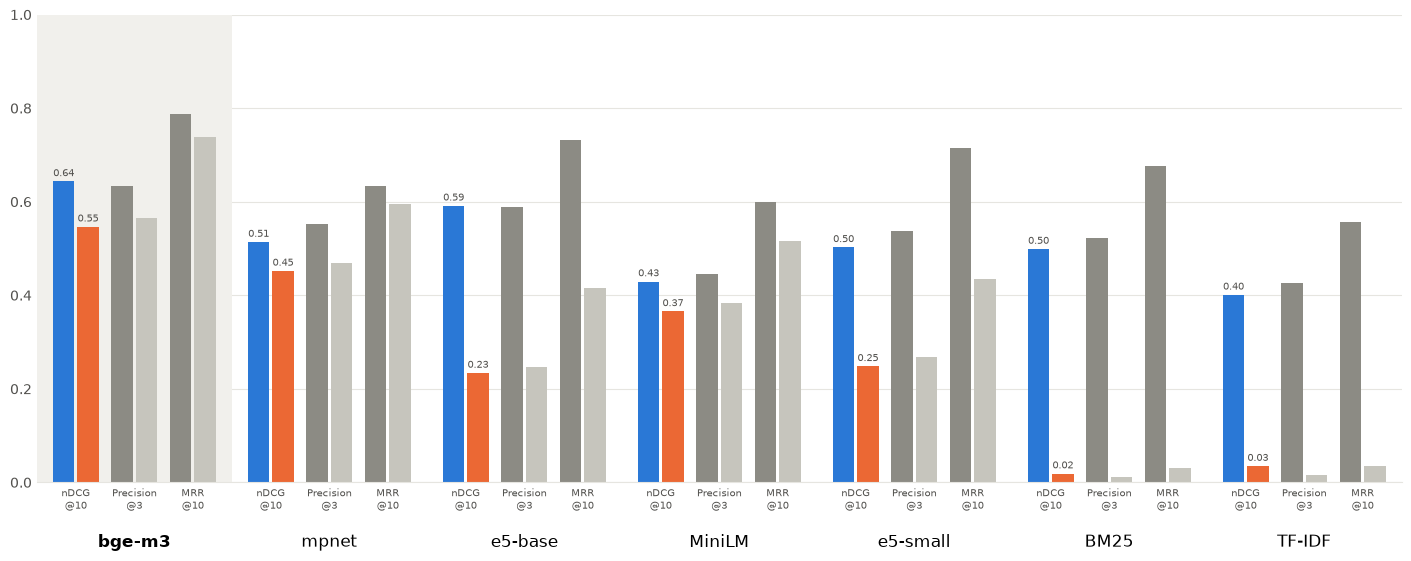

In [5]:
ranked_methods = list(mean_ndcg.index)
scores = summary.pivot(index="method", columns="language").loc[ranked_methods]
method_positions = np.arange(len(ranked_methods))
recommended_position = ranked_methods.index(recommended_model)
score_offsets = np.array([-0.3, 0, 0.3])
bar_width = 0.125

figure, axis = plt.subplots(figsize=(14, 5.5), layout="constrained")
axis.axvspan(
    recommended_position - 0.5,
    recommended_position + 0.5,
    color=RECOMMENDED_BAND_COLOR,
    linewidth=0,
)
for score_offset, score in zip(score_offsets, SCORE_NAMES, strict=True):
    is_selection_score = score == SELECTION_SCORE
    colors = BAR_COLORS[SCORE_NAMES[score] if is_selection_score else "Other scores"]
    for bar_offset, language in zip([-bar_width / 2, bar_width / 2], LANGUAGE_NAMES, strict=True):
        bars = axis.bar(
            method_positions + score_offset + bar_offset,
            scores[(score, language)],
            width=bar_width - 0.015,
            color=colors[language],
        )
        if is_selection_score:
            axis.bar_label(bars, fmt="%.2f", padding=2, fontsize=7.5, color=TEXT_COLOR)

axis.set_xticks(
    (method_positions[:, None] + score_offsets).ravel(),
    [name.replace("@", "\n@") for name in SCORE_NAMES.values()] * len(ranked_methods),
    fontsize=7.5,
)
axis.set_xlim(-0.5, len(ranked_methods) - 0.5)
axis.set_ylim(0, 1)
axis.grid(axis="y", color=GRID_COLOR)
axis.set_axisbelow(True)
axis.spines[["top", "right", "left"]].set_visible(False)
axis.spines["bottom"].set_color(GRID_COLOR)
axis.tick_params(length=0, labelcolor=TEXT_COLOR)

method_axis = axis.secondary_xaxis(-0.1)
method_axis.set_xticks(
    method_positions, [METHOD_NAMES[method] for method in ranked_methods], fontsize=12
)
method_axis.spines["bottom"].set_visible(False)
method_axis.tick_params(length=0)
method_axis.get_xticklabels()[recommended_position].set_fontweight("bold")

figure.savefig(FIGURES_DIR / "scores.png", dpi=200)
plt.show()